In [1]:
import numpy as np
import scipy.sparse as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import Fstar

from utils import *
import utils

In [24]:
# Run this first to convert raw files from https://snap.stanford.edu/data/index.html
# to nice scipy formats

# import numpy as np
# import scipy.sparse as sp
# import sknetwork as sn

# data = [
#     ("amazon", "com-amazon.ungraph.txt", "com-amazon.all.dedup.cmty.txt", "com-amazon.top5000.cmty.txt"),
#     ("dblp", "com-dblp.ungraph.txt", "com-dblp.all.cmty.txt", "com-dblp.top5000.cmty.txt"),
#     ("youtube", "com-youtube.ungraph.txt", "com-youtube.all.cmty.txt", "com-youtube.top5000.cmty.txt")
# ]

# for name, adj_file, lab_file, tlab_file in data:
#     print(name)
#     adjacency = sn.data.from_csv(f"{adj_file}", comments="#")
#     adjacency = adjacency.astype("bool")

#     with open(f"{lab_file}", "r") as f:
#         x = f.readlines()
#         labels = sp.dok_matrix((len(x), adjacency.shape[0]), dtype="bool")
#         for c, line in enumerate(x):
#             nodes = line[:-1].split('\t')
#             for n in nodes:
#                 labels[c, int(n)] = True
#     labels = labels.tocsc()

#     with open(f"{tlab_file}", "r") as f:
#         x = f.readlines()
#         tlabels = sp.dok_matrix((len(x), adjacency.shape[0]), dtype="bool")
#         for c, line in enumerate(x):
#             nodes = line[:-1].split('\t')
#             for n in nodes:
#                 tlabels[c, int(n)] = True
#     tlabels = tlabels.tocsc()

#     # Drop empty nodes
#     keep_nodes = np.asarray(adjacency.sum(axis=1) > 0).reshape(-1)
#     adjacency = adjacency[keep_nodes][:, keep_nodes]
#     labels = labels[:, keep_nodes]
#     tlabels = tlabels[:, keep_nodes]

#     sp.save_npz(f"{name}_adjacency.npz", adjacency)
#     sp.save_npz(f"{name}_labels.npz", labels.tocsr())
#     sp.save_npz(f"{name}_tlabels.npz", tlabels.tocsr())
#     print("Done ", name)


amazon
Done  amazon
dblp
Done  dblp
youtube
Done  youtube


In [2]:
# for name in ["amazon", "dblp", "youtube"]:
#     adj = sp.load_npz(f"{name}_adjacency.npz")

#     print(name, "LC+HSLC")
#     c = lc_hslc(adj)
#     sp.save_npz(f"{name}_lchslc.npz", c)

#     print(name, "EGOSPLIT+CAS")
#     c = egosplit_cas(adj)
#     sp.save_npz(f"{name}_egosplitcas.npz", c)

#     # This takes a while
#     print(name, "OSLOM")
#     c = oslom(adj)
#     sp.save_npz(f"{name}_oslom.npz", c)

youtube LC+HSLC


: 

In [19]:
data = []
for name in ["dblp", "amazon", "youtube"]:
    print(name)
    adj = sp.load_npz(f"real/{name}_adjacency.npz")
    lab = sp.load_npz(f"real/{name}_labels.npz")
    elab = Fstar.node_clustering_to_edge_clustering(adj, lab)
    for method, method_name in zip(["lchslc", "egosplitcas", "oslom"], ["LC+HSLC", "EGOSPLIT+CAS", "OSLOM"]):
        if name == "youtube" and method == "lchslc":
            continue
        print(method)
        p = sp.load_npz(f"real/{name}_{method}.npz")
        data.append([name.capitalize(), method_name, "Node", Fstar.fstar(p, lab)])
        ep = Fstar.node_clustering_to_edge_clustering(adj, p)
        data.append([name.capitalize(), method_name, "Edge", Fstar.fstar(ep, elab)])

df = pd.DataFrame(data, columns=['name', 'method', 'type', 'value'])

dblp
lchslc
egosplitcas
oslom
amazon
lchslc
egosplitcas
oslom
youtube
egosplitcas
oslom


In [20]:
df

,name,method,type,value
0,Dblp,LC+HSLC,Node,0.145103
1,Dblp,LC+HSLC,Edge,0.137812
2,Dblp,EGOSPLIT+CAS,Node,0.139908
3,Dblp,EGOSPLIT+CAS,Edge,0.114433
4,Dblp,OSLOM,Node,0.148176
5,Dblp,OSLOM,Edge,0.129728
6,Amazon,LC+HSLC,Node,0.201191
7,Amazon,LC+HSLC,Edge,0.188293
8,Amazon,EGOSPLIT+CAS,Node,0.189019
9,Amazon,EGOSPLIT+CAS,Edge,0.196134


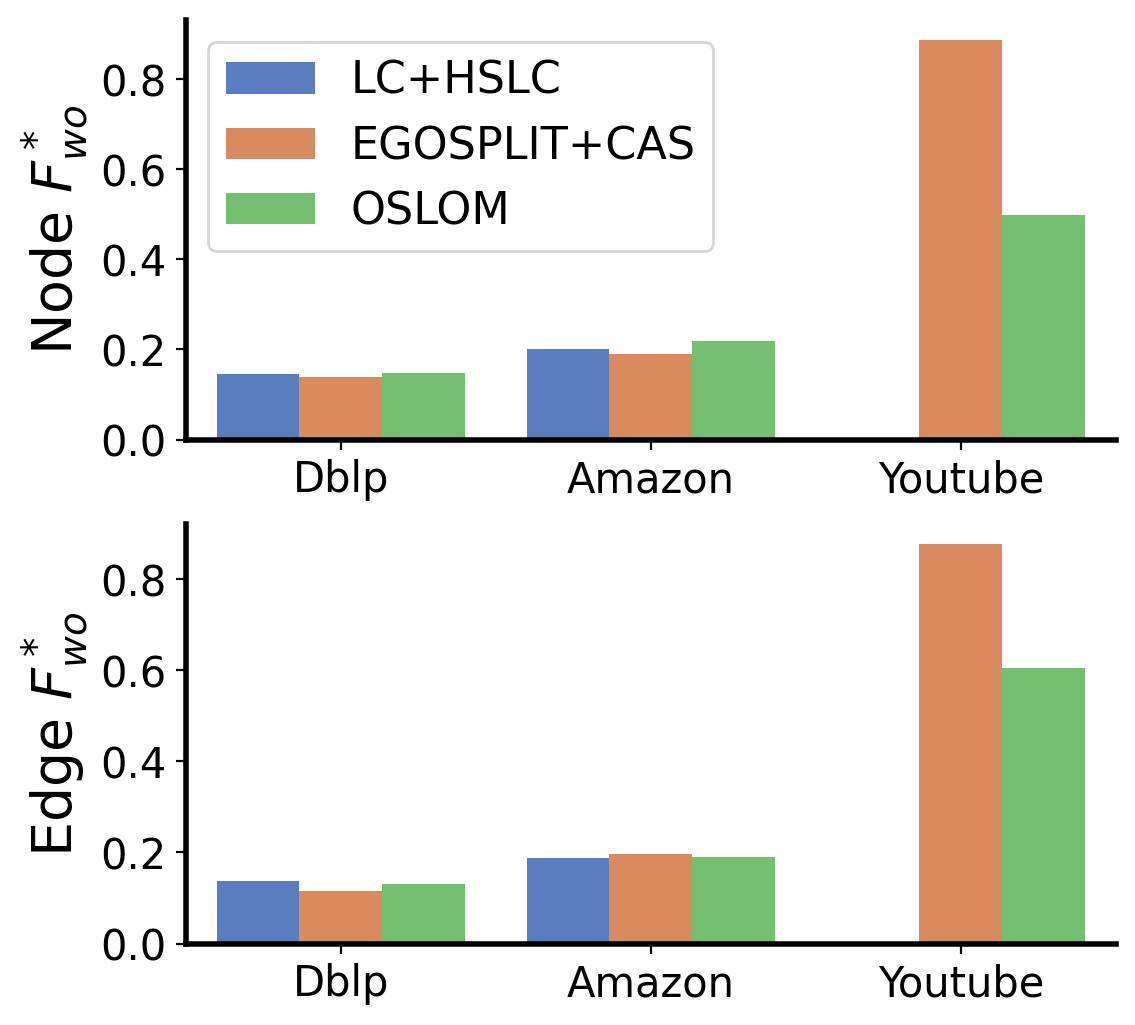

In [21]:
fig, axs = plt.subplots(2, 1, figsize=(6, 6), dpi=200)
sns.barplot(df[df["type"] == "Node"], x="name", y="value", hue="method", ax=axs[0], palette="muted", errorbar=("pi", 100))
sns.barplot(df[df["type"] == "Edge"], x="name", y="value", hue="method", ax=axs[1], palette="muted", errorbar=("pi", 100), legend=False)
axs[0].set_ylabel(r"Node $F^*_{wo}$", fontsize=20)
axs[1].set_ylabel(r"Edge $F^*_{wo}$", fontsize=20)
# Decorations
for ax in axs:
    for spine in ['right', 'top']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(2)
    ax.tick_params(labelsize=15)
    ax.set_xlabel("")
axs[0].legend(fancybox=True, fontsize=16)
plt.savefig('real_all.pdf', bbox_inches='tight');

In [2]:
data = []
for name in ["dblp", "amazon", "youtube"]:
    print(name)
    adj = sp.load_npz(f"real/{name}_adjacency.npz")
    lab = sp.load_npz(f"real/{name}_tlabels.npz")
    elab = Fstar.node_clustering_to_edge_clustering(adj, lab)
    for method, method_name in zip(["lchslc", "egosplitcas", "oslom"], ["LC+HSLC", "EGOSPLIT+CAS", "OSLOM"]):
        if name == "youtube" and method == "lchslc":
            continue
        print(method)
        p = sp.load_npz(f"real/{name}_{method}.npz")
        data.append([name.capitalize(), method_name, "Node", Fstar.fstar(p, lab, alpha=1, outliers=False)])
        ep = Fstar.node_clustering_to_edge_clustering(adj, p)
        data.append([name.capitalize(), method_name, "Edge", Fstar.fstar(ep, elab, alpha=1, outliers=False)])

df = pd.DataFrame(data, columns=['name', 'method', 'type', 'value'])

dblp
lchslc
egosplitcas
oslom
amazon
lchslc
egosplitcas
oslom
youtube
egosplitcas
oslom


In [3]:
df

,name,method,type,value
0,Dblp,LC+HSLC,Node,0.100840
1,Dblp,LC+HSLC,Edge,0.097444
2,Dblp,EGOSPLIT+CAS,Node,0.218906
3,Dblp,EGOSPLIT+CAS,Edge,0.203454
4,Dblp,OSLOM,Node,0.125356
5,Dblp,OSLOM,Edge,0.125594
6,Amazon,LC+HSLC,Node,0.029258
7,Amazon,LC+HSLC,Edge,0.044466
8,Amazon,EGOSPLIT+CAS,Node,0.067001
9,Amazon,EGOSPLIT+CAS,Edge,0.076959


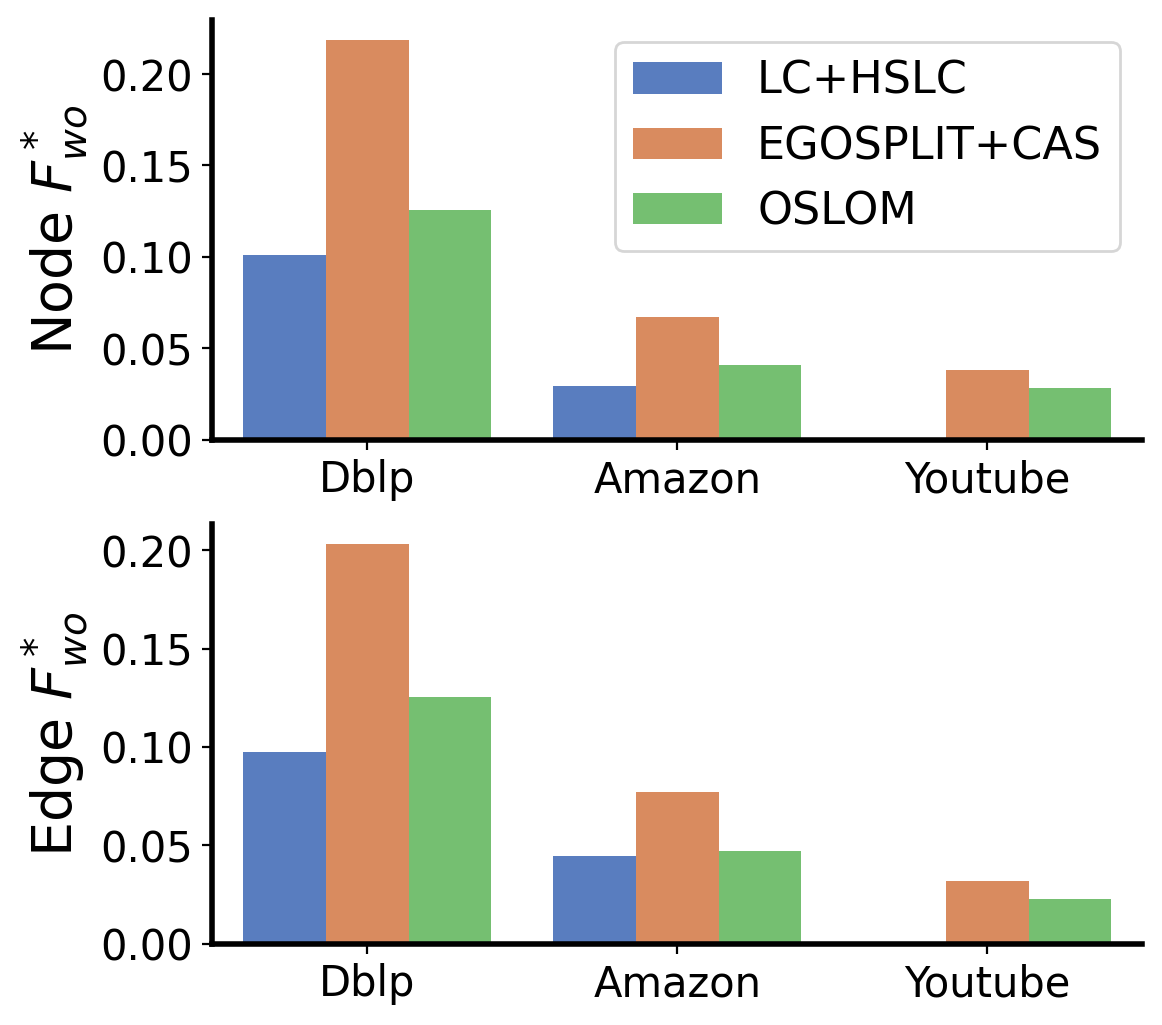

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(6, 6), dpi=200)
sns.barplot(df[df["type"] == "Node"], x="name", y="value", hue="method", ax=axs[0], palette="muted", errorbar=("pi", 100))
sns.barplot(df[df["type"] == "Edge"], x="name", y="value", hue="method", ax=axs[1], palette="muted", errorbar=("pi", 100), legend=False)
axs[0].set_ylabel(r"Node $F^*_{wo}$", fontsize=20)
axs[1].set_ylabel(r"Edge $F^*_{wo}$", fontsize=20)
# Decorations
for ax in axs:
    for spine in ['right', 'top']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(2)
    ax.tick_params(labelsize=15)
    ax.set_xlabel("")
axs[0].legend(fancybox=True, fontsize=16)
plt.savefig('real_top.pdf', bbox_inches='tight');